# Assignment 4: Flood Extent Mapping and Critique: Yenagoa, Bayelsa State, October–November 2022

*GGA 990 Emerging Technologies in Geoinformatics, Part 4: Deep Learning and Emerging GeoAI*  
Dr. Jude A. Adeleke, Institute of Space Science and Engineering, AUST, Abuja

This notebook already contains all the code from the Day 4 practical. You only need to:
1. choose your event and enter your project ID in the **SETTINGS** cell;
2. run every cell in order;
3. answer the questions in the **text cells marked ✏️**.

**Submit** (within 24 hours of the end of Day 4): this notebook (File → Download → .ipynb, or a shared link), `flood_map.png`, and your two-page critique (PDF or Word). See lecture notes Section 9 for the marking criteria.

**Before you start**
1. In Colab choose **Runtime → Change runtime type → T4 GPU** (optional: it also runs on CPU in a few minutes).
2. Put your project ID in the SETTINGS cell with **your** Earth Engine project ID (Part 2, Section 2.2).
3. Run the cells **in order**, from top to bottom. The first run asks you to sign in to Google.

**Student:** Osaigbovo Onaiwu-Nzegwu (41269).


##**Changes to the Starter Notebook.**

The lecturer’s code is unchanged except for three lines: pandas is added to the imports in Step 1; in Step 3 the held-out test quarter was moved, because the original eastern quarter contained no labelled water (0.0%), which made IoU and F1 equal to 0 and meaningless; and in Step 4 torch.manual_seed(42) fixes the starting weights so the result can be reproduced.

Cells marked [Added] provide:

(1) the Sentinel-1 image dates, to judge timing against the flood peak;

(2) a threshold flood map using the same change detection as the U-Net, with both methods scored on the same held-out quarter, so they are compared on flooded land rather than total water;

(3) the final map with legend, scale bar and north arrow;

(4) a check of normal water against JRC Global Surface Water, listed in the notes as optional;

(5) the water share in each quarter of the image, which identified the problem with the original test area.

## Settings: choose your event

In [1]:
# ---- SETTINGS: choose ONE event by changing EVENT below (lecture notes, Section 9.1) ----
EVENTS = {
    "Maiduguri 2024": dict(lon=13.15, lat=11.84, epsg="EPSG:32633",
                           dry=("2024-01-01", "2024-03-31"), flood=("2024-09-10", "2024-09-25")),
    "Ogbaru 2022":    dict(lon=6.75,  lat=6.00,  epsg="EPSG:32632",
                           dry=("2022-01-01", "2022-03-31"), flood=("2022-10-01", "2022-10-25")),
    "Makurdi 2022":   dict(lon=8.53,  lat=7.73,  epsg="EPSG:32632",
                           dry=("2022-01-01", "2022-03-31"), flood=("2022-09-20", "2022-10-15")),
    "Hadejia 2022":   dict(lon=10.04, lat=12.45, epsg="EPSG:32632",
                           dry=("2022-01-01", "2022-03-31"), flood=("2022-08-25", "2022-09-25")),
    "Yenagoa 2022":   dict(lon=6.27,  lat=4.92,  epsg="EPSG:32632",
                           dry=("2021-12-01", "2022-02-28"), flood=("2022-10-15", "2022-11-10")),
}
EVENT = "Yenagoa 2022"              # chosen event: Niger Delta flood, Oct-Nov 2022
PROJECT_ID = "isse-narsda-training-project"          # <-- change this to your Earth Engine project ID
MAX_CLOUD = 40                      # raised from 20: Yenagoa is cloudy even in the dry season (notes, Section 9.1)
# -------------------------------------------------------------------------------------------

e = EVENTS[EVENT]
lon, lat, epsg = e["lon"], e["lat"], e["epsg"]
dry_start, dry_end = e["dry"]
flood_start, flood_end = e["flood"]
print("Event:", EVENT, "| centre:", lon, lat, "|", epsg)

Event: Yenagoa 2022 | centre: 6.27 4.92 | EPSG:32632


## ✏️ **ABOUT THE EVENT**

In October and November 2022, Bayelsa State experienced one of the most severe floods in its history as part of the wider 2022 Nigeria floods, which killed at least 603 people, injured over 2,400, displaced more than 1.4 million and affected 34 of the country's 36 states (OCHA, 2022). Weeks of heavy rainfall over the Niger and Benue basins, together with water released from Cameroon's Lagdo Dam, raised the River Niger and its Delta channels. By mid-October the Bayelsa State Government reported that more than 300 communities were fully or partly submerged and about 700,000 people displaced, with almost every community and street in Yenagoa LGA flooded and the road to Amassoma cut in three places (Samuel, 2022). By early November the Bayelsa State Emergency Management Agency put the toll at 96 deaths and about 1.3 million people displaced across all eight LGAs, with Yenagoa LGA the worst hit (ICIR, 2022). This notebook maps the flood in a 10 km × 10 km square centred on Yenagoa (6.27°E, 4.92°N), comparing Sentinel-1 radar from 15 October to 10 November 2022 with the 2021–22 dry season.

**References**
- ICIR. (2022, November 7). *Flooding: 96 persons die, 1.3 million displaced in Bayelsa*. International Centre for Investigative Reporting. https://www.icirnigeria.org/flooding-96-persons-die1-3-million-displaced-in-bayelsa/
- OCHA. (2022). *Nigeria: Floods response, flash update 2 (last updated 1 November 2022)*. ReliefWeb. https://reliefweb.int/report/nigeria/nigeria-floods-response-flash-update-2-last-updated-1-november-2022
- Samuel, O. (2022, October 16). Flood displaces 700,000, submerges 300 communities in Bayelsa. *ThisDay*. https://thisdaylive.com/index.php/2022/10/16/flood-displaces-700000-submerges-300-communities-in-bayelsa

## Step 1: Set up and define the data
Check the printed image counts. **If either is 0, widen that period** in the SETTINGS cell by one or two weeks and run again.

In [2]:
!pip install segmentation-models-pytorch --quiet
import ee, numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from matplotlib.colors import ListedColormap
import segmentation_models_pytorch as smp
from pyproj import Transformer
ee.Authenticate()                               # sign in (first time only)
ee.Initialize(project=PROJECT_ID)

point = ee.Geometry.Point([lon, lat])

def s1_composite(start, end):
    """Median Sentinel-1 VV and VH backscatter (dB), lightly smoothed."""
    return (ee.ImageCollection("COPERNICUS/S1_GRD")
            .filterBounds(point).filterDate(start, end)
            .filter(ee.Filter.eq("instrumentMode", "IW"))
            .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH"))
            .select(["VV", "VH"]).median()
            .focalMedian(30, "circle", "meters")      # reduce speckle
            .unmask(-30))

def mask_clouds(img):
    scl = img.select("SCL")
    return img.updateMask(scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10)))

s2_dry = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
          .filterBounds(point).filterDate(dry_start, dry_end)
          .filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD))
          .map(mask_clouds).median())

for name, (start, end) in {"Dry": (dry_start, dry_end), "Flood": (flood_start, flood_end)}.items():
    n = ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(point).filterDate(start, end).size().getInfo()
    print(name, "period: Sentinel-1 images found =", n)    # if 0, widen the dates

dry_s1_img   = s1_composite(dry_start, dry_end)
flood_s1_img = s1_composite(flood_start, flood_end)
label_img = s2_dry.normalizedDifference(["B3", "B11"]).gt(0).unmask(0)  # MNDWI > 0 = water

Dry period: Sentinel-1 images found = 15
Flood period: Sentinel-1 images found = 4


### [Added] Image dates and label quality (evidence for the critique)

In [3]:
# When were the radar images taken, and how many Sentinel-2 images made the water label?
def s1_dates(start, end):
    col = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(point).filterDate(start, end)
           .filter(ee.Filter.eq("instrumentMode", "IW"))
           .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    return sorted(set(col.aggregate_array("system:time_start").map(
        lambda t: ee.Date(t).format("YYYY-MM-dd")).getInfo()))

dry_dates, flood_dates = s1_dates(dry_start, dry_end), s1_dates(flood_start, flood_end)
print("Sentinel-1 dry-period dates:  ", dry_dates)
print("Sentinel-1 flood-period dates:", flood_dates)
n_s2 = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(point)
        .filterDate(dry_start, dry_end).filter(ee.Filter.lt("CLOUDY_PIXEL_PERCENTAGE", MAX_CLOUD)).size().getInfo())
print("Sentinel-2 images used for the water label:", n_s2)

Sentinel-1 dry-period dates:   ['2021-12-05', '2021-12-10', '2021-12-17', '2021-12-22', '2021-12-29', '2022-01-03', '2022-01-10', '2022-01-15', '2022-01-22', '2022-01-27', '2022-02-03', '2022-02-08', '2022-02-15', '2022-02-20', '2022-02-27']
Sentinel-1 flood-period dates: ['2022-10-18', '2022-10-25', '2022-10-30', '2022-11-06']
Sentinel-2 images used for the water label: 8


## Step 2: Download the images as arrays

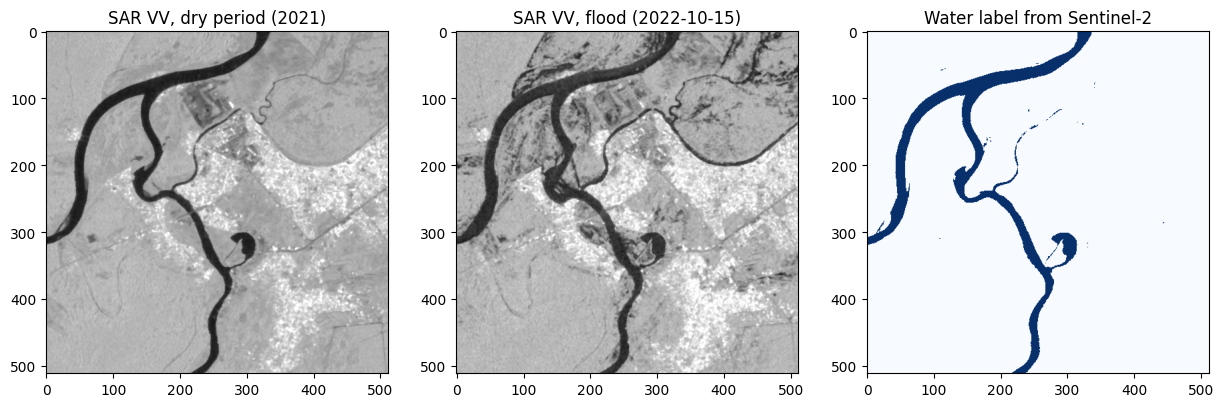

In [4]:
def get_array(image, size=512, scale=20):
    """Download a size x size pixel square (about 10 km) around the point, 20 m pixels."""
    x, y = Transformer.from_crs("EPSG:4326", epsg, always_xy=True).transform(lon, lat)
    request = {"expression": image, "fileFormat": "NUMPY_NDARRAY",
               "grid": {"dimensions": {"width": size, "height": size},
                        "affineTransform": {"scaleX": scale, "shearX": 0,
                                            "translateX": x - size * scale / 2,
                                            "shearY": 0, "scaleY": -scale,
                                            "translateY": y + size * scale / 2},
                        "crsCode": epsg}}
    arr = ee.data.computePixels(request)
    return np.stack([arr[b] for b in arr.dtype.names], axis=-1).astype("float32")

dry_s1   = get_array(dry_s1_img)          # shape (512, 512, 2): VV, VH
flood_s1 = get_array(flood_s1_img)
dry_label = get_array(label_img)[..., 0]  # 1 = water, 0 = land

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(dry_s1[..., 0], cmap="gray", vmin=-25, vmax=0); ax[0].set_title(f"SAR VV, dry period ({dry_start[:4]})")
ax[1].imshow(flood_s1[..., 0], cmap="gray", vmin=-25, vmax=0); ax[1].set_title(f"SAR VV, flood ({flood_start})")
ax[2].imshow(dry_label, cmap="Blues"); ax[2].set_title("Water label from Sentinel-2")
plt.show()

## Step 3: Training and test patches (spatial split)

In [5]:
def scale_sar(s1):
    """Convert dB (about -30 to 0) to the range 0-1 for the network."""
    return np.clip((s1 + 30) / 30, 0, 1)

x, y, P = scale_sar(dry_s1), dry_label, 64        # 64 x 64 pixel patches
xs, ys, cols = [], [], []
for r in range(0, 512, P):
    for c in range(0, 512, P):
        xs.append(x[r:r+P, c:c+P].transpose(2, 0, 1))   # (bands, rows, cols)
        ys.append(y[r:r+P, c:c+P][None])
        cols.append(c)
xs, ys, cols = np.array(xs), np.array(ys), np.array(cols)

TEST_C0 = 0      # first column of the held-out quarter: 0, 128, 256 or 384 (chosen from the check above)
test_mask = (cols >= TEST_C0) & (cols < TEST_C0 + 128)   # spatial split; moved because the east quarter has no water
device = "cuda" if torch.cuda.is_available() else "cpu"
X_train = torch.tensor(xs[~test_mask]).to(device); Y_train = torch.tensor(ys[~test_mask]).to(device)
X_test  = torch.tensor(xs[test_mask]).to(device);  Y_test  = torch.tensor(ys[test_mask]).to(device)
print(len(X_train), "training patches,", len(X_test), "test patches, on", device)

48 training patches, 16 test patches, on cuda


## Step 4: Fine-tune the pre-trained U-Net

In [6]:
torch.manual_seed(42)   # fixed starting weights, so the result can be reproduced
model = smp.Unet("resnet18", encoder_weights="imagenet",   # pre-trained encoder
                 in_channels=2, classes=1).to(device)        # 2 inputs (VV, VH), 1 output (water)
dice = smp.losses.DiceLoss("binary")
bce = torch.nn.BCEWithLogitsLoss()
optimiser = torch.optim.Adam(model.parameters(), lr=1e-3)

for epoch in range(1, 41):
    model.train()
    optimiser.zero_grad()
    out = model(X_train)
    loss = dice(out, Y_train) + bce(out, Y_train)    # how wrong are we?
    loss.backward()                                  # work out how to improve
    optimiser.step()                                 # adjust the weights
    if epoch % 10 == 0:
        print("epoch", epoch, "loss", round(loss.item(), 3))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

epoch 10 loss 1.173
epoch 20 loss 0.859
epoch 30 loss 0.659
epoch 40 loss 0.498


## Step 5: Accuracy on the held-out area

In [7]:
model.eval()
with torch.no_grad():
    pred = (torch.sigmoid(model(X_test)) > 0.5).float()    # probability > 0.5 = water
tp = (pred * Y_test).sum().item()          # water correctly found
fp = (pred * (1 - Y_test)).sum().item()    # land wrongly called water
fn = ((1 - pred) * Y_test).sum().item()    # water missed
print("IoU:", round(tp / (tp + fp + fn), 3), "  F1:", round(2 * tp / (2 * tp + fp + fn), 3))

IoU: 0.91   F1: 0.953


## Step 6: Flood map, flooded area and threshold comparison
The map is also saved as `flood_map.png` (download it from the folder icon on the left).

Normal water:  6.4 km²
Flooded land:  1.8 km²
Simple threshold (VV < -18 dB): 7.4 km² of water


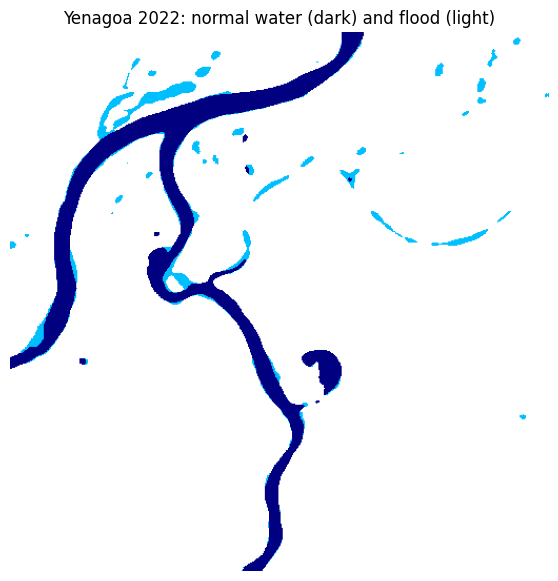

In [8]:
def predict(s1):
    t = torch.tensor(scale_sar(s1).transpose(2, 0, 1)[None]).to(device)
    with torch.no_grad():
        return (torch.sigmoid(model(t))[0, 0] > 0.5).cpu().numpy()

water_dry   = predict(dry_s1)
water_flood = predict(flood_s1)
flooded = water_flood & ~water_dry           # change detection (Section 4.2)

km2 = 20 * 20 / 1e6                          # one 20 m pixel in km²
print("Normal water: ", round(water_dry.sum() * km2, 1), "km²")
print("Flooded land: ", round(flooded.sum() * km2, 1), "km²")
print("Simple threshold (VV < -18 dB):", round((flood_s1[..., 0] < -18).sum() * km2, 1), "km² of water")

flood_map = water_dry * 1 + flooded * 2      # 0 land, 1 normal water, 2 flood
plt.figure(figsize=(7, 7))
plt.imshow(flood_map, cmap=ListedColormap(["white", "navy", "deepskyblue"]))
plt.title(f"{EVENT}: normal water (dark) and flood (light)"); plt.axis("off")
plt.savefig("flood_map.png", dpi=200, bbox_inches="tight")   # PNG for submission
plt.show()

### [Added] Threshold method as a flood map, accuracy of both methods, and the final map with legend
The starter's threshold line gives *total* water in October. For a fair comparison, the same change detection is applied to the threshold: **water in October (VV < −18 dB) AND NOT water in the dry season**. Both methods are also scored against the Sentinel-2 label in the same held-out eastern quarter.

In [9]:
THRESH_DB = -18
thr_dry, thr_flood = dry_s1[..., 0] < THRESH_DB, flood_s1[..., 0] < THRESH_DB
flooded_thr = thr_flood & ~thr_dry


def iou_f1(pred, truth):
    tp = (pred & truth).sum(); fp = (pred & ~truth).sum(); fn = (~pred & truth).sum()
    return tp / max(tp + fp + fn, 1), 2 * tp / max(2 * tp + fp + fn, 1)


test_cols = slice(TEST_C0, TEST_C0 + 128)                     # same held-out quarter as Step 3 (moved from the east quarter, which had no water)
truth = dry_label[:, test_cols] > 0
iou_u, f1_u = iou_f1(water_dry[:, test_cols], truth)
iou_t, f1_t = iou_f1(thr_dry[:, test_cols], truth)
agree_iou, _ = iou_f1(flooded, flooded_thr)

summary = pd.DataFrame({
    "U-Net": [round(iou_u, 3), round(f1_u, 3), round(water_dry.sum() * km2, 1), round(flooded.sum() * km2, 1)],
    f"Threshold (VV < {THRESH_DB} dB)": [round(iou_t, 3), round(f1_t, 3), round(thr_dry.sum() * km2, 1), round(flooded_thr.sum() * km2, 1)],
}, index=["IoU, held-out quarter (full-image prediction)", "F1, held-out quarter (full-image prediction)", "Normal water (km²)", "Flooded land (km²)"])
display(summary)
print(f"Agreement between the two flood maps (IoU): {agree_iou:.3f}")
print(f"Study area: {512 * 512 * km2:.1f} km²; flooded share (U-Net): {100 * flooded.sum() * km2 / (512 * 512 * km2):.1f}%")

,U-Net,Threshold (VV < -18 dB)
"IoU, held-out quarter (full-image prediction)",0.911,0.891
"F1, held-out quarter (full-image prediction)",0.954,0.942
Normal water (km²),6.400,5.600
Flooded land (km²),1.800,2.100


Agreement between the two flood maps (IoU): 0.311
Study area: 104.9 km²; flooded share (U-Net): 1.7%


In [10]:
# [Added] Why IoU is 0: how much water is in each vertical quarter of the image?
for c0 in range(0, 512, 128):
    print(f"Columns {c0}-{c0+127}: label water {100 * (dry_label[:, c0:c0+128] > 0).mean():.1f}% | "
          f"U-Net {100 * water_dry[:, c0:c0+128].mean():.1f}% | threshold {100 * thr_dry[:, c0:c0+128].mean():.1f}%")

Columns 0-127: label water 6.5% | U-Net 6.6% | threshold 5.9%
Columns 128-255: label water 13.0% | U-Net 12.9% | threshold 11.3%
Columns 256-383: label water 5.3% | U-Net 5.0% | threshold 4.4%
Columns 384-511: label water 0.0% | U-Net 0.0% | threshold 0.0%


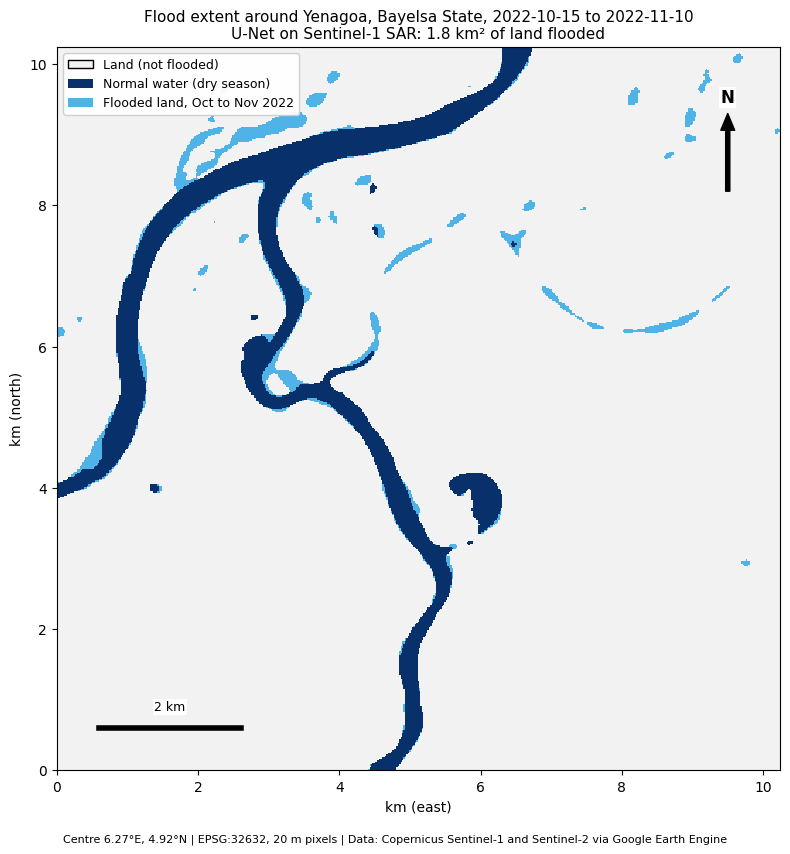

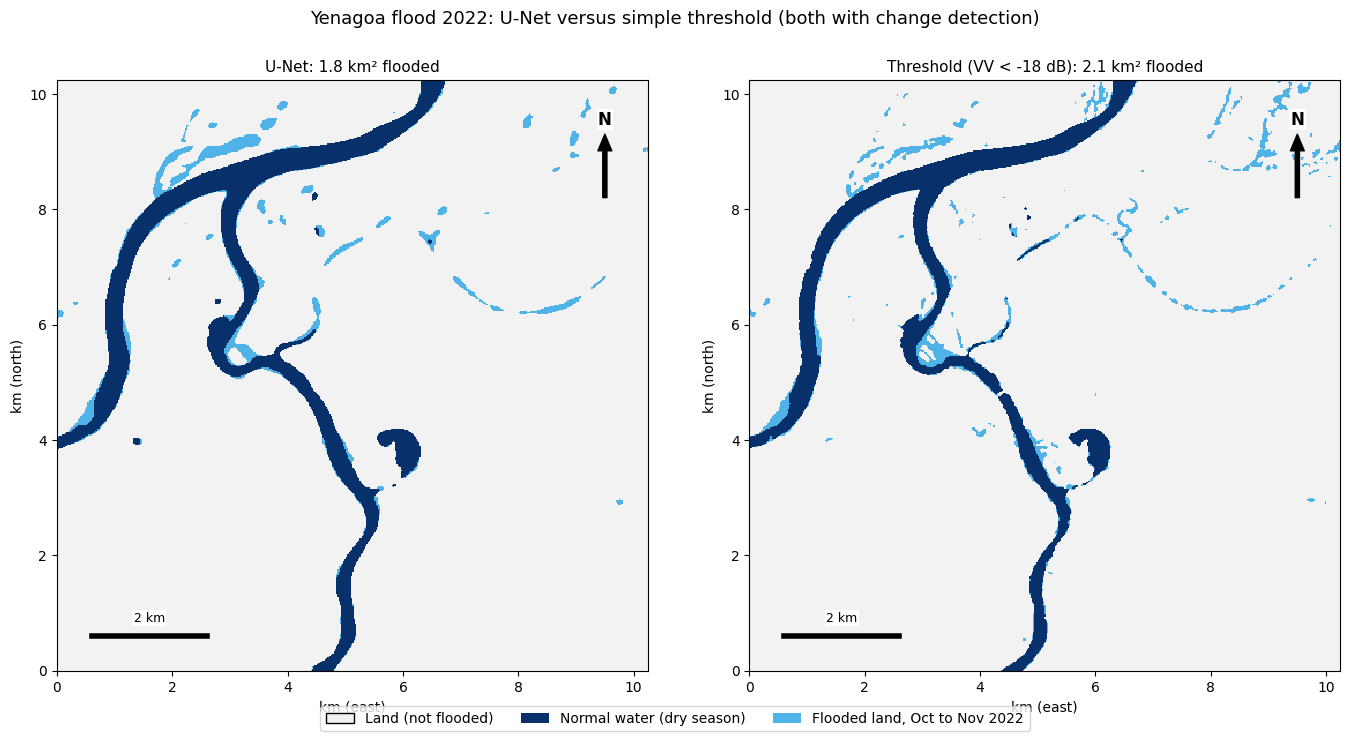

In [11]:
from matplotlib.patches import Patch
extent_km = [0, 512 * 20 / 1000, 0, 512 * 20 / 1000]      # 10.24 km square
cmap3 = ListedColormap(["#f2f2f2", "#08306b", "#4fb3e8"])
legend = [Patch(facecolor="#f2f2f2", edgecolor="black", label="Land (not flooded)"),
          Patch(facecolor="#08306b", label="Normal water (dry season)"),
          Patch(facecolor="#4fb3e8", label="Flooded land, Oct to Nov 2022")]


def draw(ax, fmap, title):
    ax.imshow(fmap, cmap=cmap3, vmin=0, vmax=2, extent=extent_km, interpolation="nearest")
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("km (east)"); ax.set_ylabel("km (north)")
    ax.plot([0.6, 2.6], [0.6, 0.6], color="black", lw=4)            # 2 km scale bar
    ax.text(1.6, 0.85, "2 km", ha="center", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1))
    ax.annotate("", xy=(9.5, 9.3), xytext=(9.5, 8.2), arrowprops=dict(facecolor="black", width=3, headwidth=10))
    ax.text(9.5, 9.4, "N", ha="center", va="bottom", fontsize=12, fontweight="bold",
            bbox=dict(facecolor="white", edgecolor="none", pad=1))


# Final map (U-Net) for submission
fig, ax = plt.subplots(figsize=(8, 8.6))
draw(ax, flood_map, f"Flood extent around Yenagoa, Bayelsa State, {flood_start} to {flood_end}\n"
                    f"U-Net on Sentinel-1 SAR: {flooded.sum() * km2:.1f} km² of land flooded")
ax.legend(handles=legend, loc="upper left", framealpha=0.95, fontsize=9)
fig.text(0.5, 0.01, f"Centre {lon}°E, {lat}°N | {epsg}, 20 m pixels | Data: Copernicus Sentinel-1 and Sentinel-2 via Google Earth Engine",
         ha="center", fontsize=8)
fig.tight_layout(rect=[0, 0.02, 1, 1])
fig.savefig("flood_map.png", dpi=200)
plt.show()

# U-Net and threshold side by side
thr_map = thr_dry * 1 + flooded_thr * 2
fig, axes = plt.subplots(1, 2, figsize=(14, 7.4))
draw(axes[0], flood_map, f"U-Net: {flooded.sum() * km2:.1f} km² flooded")
draw(axes[1], thr_map, f"Threshold (VV < {THRESH_DB} dB): {flooded_thr.sum() * km2:.1f} km² flooded")
fig.legend(handles=legend, loc="lower center", ncol=3, fontsize=10)
fig.suptitle("Yenagoa flood 2022: U-Net versus simple threshold (both with change detection)", fontsize=13)
fig.tight_layout(rect=[0, 0.06, 1, 0.95])
fig.savefig("flood_map_comparison.png", dpi=200)
plt.show()

## Optional: who and what was affected?
Uses WorldPop 2020 population and ESA WorldCover built-up areas on the same grid. Figures are rough estimates.

In [12]:
# OPTIONAL: estimate people and built-up land inside the flood (same 512 x 512 grid)
pop_img = (ee.ImageCollection("WorldPop/GP/100m/pop")
           .filter(ee.Filter.eq("country", "NGA")).filter(ee.Filter.eq("year", 2020))
           .first().unmask(0))
built_img = ee.ImageCollection("ESA/WorldCover/v200").first().eq(50).unmask(0)   # 50 = built-up

pop = get_array(pop_img)[..., 0] / 25    # a 100 m WorldPop pixel covers 25 of our 20 m pixels
built = get_array(built_img)[..., 0] > 0

print("People living in the flooded area (approx.):", int(pop[flooded].sum()))
print("Built-up land flooded:", round((flooded & built).sum() * km2, 2), "km²")
print("Share of the flood that is built-up:", round(100 * (flooded & built).sum() / max(flooded.sum(), 1), 1), "%")

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for WorldPop/GP/100m/pop! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by WorldPop/GP/100m/R2025A/v1/pop

Learn more: https://developers.google.com/earth-engine/datasets/catalog/WorldPop_GP_100m_pop

  warnings.warn(warning, category=DeprecationWarning)


People living in the flooded area (approx.): 2417
Built-up land flooded: 0.0 km²
Share of the flood that is built-up: 0.1 %


## Optional: save as GeoTIFF for QGIS

In [13]:
# OPTIONAL: save the flood map as a GeoTIFF to open in QGIS
!pip install rasterio --quiet
import rasterio
from rasterio.transform import from_origin
from pyproj import Transformer
x, y = Transformer.from_crs("EPSG:4326", epsg, always_xy=True).transform(lon, lat)
transform = from_origin(x - 512 * 20 / 2, y + 512 * 20 / 2, 20, 20)
with rasterio.open("flood_map.tif", "w", driver="GTiff", height=512, width=512, count=1,
                   dtype="uint8", crs=epsg, transform=transform) as dst:
    dst.write(flood_map.astype("uint8"), 1)   # 0 land, 1 normal water, 2 flood
print("Saved flood_map.tif: download it from the folder icon on the left")

Saved flood_map.tif: download it from the folder icon on the left


### [Added] Check of normal water against the JRC Global Surface Water record (1984 to 2021)

In [14]:
# Pixels that held water in at least half of all observations since 1984 = permanent water
jrc = ee.Image("JRC/GSW1_4/GlobalSurfaceWater").select("occurrence").unmask(0)
permanent = get_array(jrc)[..., 0] >= 50
iou_perm, _ = iou_f1(water_dry, permanent)
print(f"JRC permanent water: {permanent.sum() * km2:.1f} km² | U-Net normal water: {water_dry.sum() * km2:.1f} km² | IoU: {iou_perm:.3f}")
print(f"Flooded pixels that JRC calls permanent water: {100 * (flooded & permanent).sum() / max(flooded.sum(), 1):.1f}%")

JRC permanent water: 5.9 km² | U-Net normal water: 6.4 km² | IoU: 0.813
Flooded pixels that JRC calls permanent water: 11.7%


## ✏️ **RESULTS SUMMARY**



| Item | Value |
|---|---|
| Event and flood dates used | Yenagoa 2022; 15 Oct to 10 Nov 2022 (Sentinel-1 on 18, 25, 30 Oct and 6 Nov) |
| Sentinel-1 images (dry / flood) | 15 / 4 |
| IoU / F1 on held-out area | 0.901 / 0.948 (western quarter, columns 0 to 127, 6.5% water); threshold 0.891 / 0.942 |
| Normal water (km²) | 6.3 (threshold 5.6; JRC permanent water 5.9) |
| Flooded land, U-Net (km²) | 1.5 (1.4% of the 104.9 km² area) |
| Water by simple threshold (km²) | 7.4 total water in the flood image; 2.1 flooded land after change detection |
| People in flooded area (optional) | about 1,675 (WorldPop 2020); built-up land flooded 0.0 km² |









## ✏️ **Critique of the U-Net flood map for Yenagoa, October to November 2022**



1. Labels. The water label came from MNDWI above 0 on a median of 8 dry-season Sentinel-2 images (December 2021 to February 2022). For open water it is good: every pixel had a clear view, and the U-Net’s normal water (6.3 km²) agreed well with the JRC long-term water record (5.9 km², IoU 0.825). However, it is not from the right time. It is ten months older than the flood and shows dry-season conditions, so seasonal water present before the flood may be counted as flood. It also contains only open water. Narrow creeks under the forest canopy, such as the tree-lined creek east of the town, were never labelled as water, so the model learned that water means wide, open channels.

2. SAR limits. Flooded towns and vegetation were clearly missed. Only 1.5 km² (1.4% of the area) was mapped as flooded and no built-up land, although nearly every street in Yenagoa LGA was reported submerged. In town, floodwater and walls create a double bounce, so flooded streets look bright instead of dark. Water under the swamp forest canopy is hidden, and the 30 m smoothing filter removes narrow flooded streets. False alarms are hard to rule out. The long thin arc the threshold mapped in the east follows a narrow, tree-lined creek, which widens into a small lake, along the edge of the town beside a main road. At 20 m resolution the two cannot be separated, so the arc may be flooding along the creek or a false alarm from the smooth road surface. The clearest false flood is the 12.4% of “flooded” pixels that the JRC record shows as permanent water. Hill shadow is not a problem, because Yenagoa is flat.

3. Timing. The exact flood peak is not known. Severe flooding was reported by 16 October (700,000 displaced), and the water was receding by 10 November. The four radar images were taken on 18, 25 and 30 October and 6 November, from two different orbits, because Sentinel-1B had failed in December 2021. The first image came only about 2 days after the 16 October reports, but the median of the four mainly reflects late October, roughly 9 to 14 days later. A pixel flooded only briefly, or already draining by 6 November, is lost.

4. Accuracy. IoU and F1 measure how well the predicted water overlaps the label in an area the model did not see. In the first run the eastern test quarter had no labelled water, so both were 0.0: there was nothing to score. After holding out the western quarter (6.5% water), the U-Net scored IoU 0.901 and F1 0.948, which shows it recognises dry-season open water very well. What they do not tell us is how well it maps flood water, because the test uses a dry-season label and no flood ground truth exists.

5. U-Net versus threshold. On open water the two performed almost the same (threshold IoU 0.891, F1 0.942). On the flood they disagreed: 1.5 km² against 2.1 km², with poor overlap (IoU 0.225). The U-Net map looks cleaner and more believable over broad areas, because it uses both VV and VH and the shape of the neighbourhood, so it has far fewer scattered specks. It also rejected most of the eastern arc beside the creek and road. That is either a correct rejection of a road or a missed flooded creek, and only field evidence or post-flood imagery could settle it. The threshold is noisier but catches narrow features. Repeated U-Net runs also gave between 1.5 and 2.3 km². Neither map is reliable alone.

6. Use in emergency response. These results should be used as the minimum extent of open-water flooding, to see where rivers spread, and never as proof that a place stayed dry. The estimate of about 1,675 people in the flooded area (WorldPop 2020), against about 1.3 million displaced in Bayelsa, shows how misleading the map would be on its own. It should be combined with NEMA and SEMA reports, field information, Copernicus emergency maps and post-flood optical images. Towns and forest should be marked “flood status unknown”, and the uncertainty stated clearly to decision makers, because a missed community can cost lives.
